<a href="https://colab.research.google.com/github/Veniveni123/CSA47-DEEP-LEARNING/blob/main/LAB%2021-30/Experiment%2026%3A%20Gibbs%20Sampling%20and%20Contrastive%20Divergence%20Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


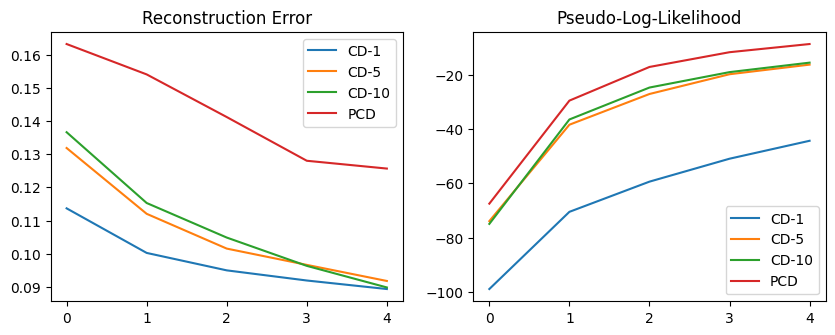

Method    MSE   PLL  Time (s)
  CD-1 0.0894 -44.3      0.27
  CD-5 0.0918 -16.3      0.99
 CD-10 0.0899 -15.5      4.24
   PCD 0.1257  -8.7      0.71


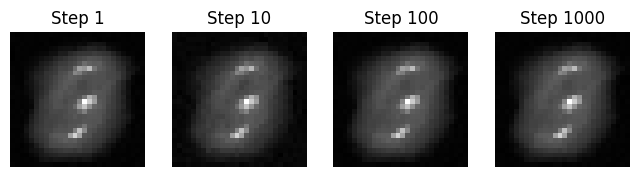

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras

np.random.seed(42)

(X_tr, _), (X_te, _) = keras.datasets.mnist.load_data()
X_train = (X_tr[:800].reshape(-1, 784) > 127).astype(np.float32)
X_test = (X_te[:100].reshape(-1, 784) > 127).astype(np.float32)
sig = lambda x: 1.0 / (1.0 + np.exp(-np.clip(x, -20, 20)))

def run_cd(k=1, pcd=False):
    W = np.random.normal(0, 0.01, (784, 32))
    a, b = np.zeros(784), np.zeros(32)
    errs, plls, chain = [], [], None
    t0 = time.time()
    for _ in range(5):
        for i in range(0, len(X_train), 50):
            v0 = X_train[i:i+50]
            ph0 = sig(v0 @ W + b)
            vk = chain if (pcd and chain is not None) else v0.copy()
            for _ in range(k):
                h = (np.random.rand(len(vk), 32) < sig(vk @ W + b)).astype(np.float32)
                pv = sig(h @ W.T + a)
                vk = (np.random.rand(*pv.shape) < pv).astype(np.float32)
                phk = sig(pv @ W + b)
            if pcd:
                chain = vk.copy()
            W += 0.05 * ((v0.T @ ph0) - (pv.T @ phk)) / len(v0)
            a += 0.05 * np.mean(v0 - pv, axis=0)
            b += 0.05 * np.mean(ph0 - phk, axis=0)
        rec = sig(sig(X_test @ W + b) @ W.T + a)
        errs.append(np.mean((X_test - rec) ** 2))
        vf = X_test.copy(); vf[:, 0] = 1 - vf[:, 0]
        fe1 = -(X_test @ a) - np.sum(np.log1p(np.exp(np.clip(X_test @ W + b, -20, 20))), axis=1)
        fe2 = -(vf @ a) - np.sum(np.log1p(np.exp(np.clip(vf @ W + b, -20, 20))), axis=1)
        plls.append(np.mean(784 * np.log(sig(fe2 - fe1) + 1e-8)))
    return W, a, b, errs, plls, round(time.time() - t0, 2)

rows = []
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for name, k, pcd in [("CD-1", 1, False), ("CD-5", 5, False), ("CD-10", 10, False), ("PCD", 1, True)]:
    W, a, b, e, p, t = run_cd(k, pcd)
    axes[0].plot(e, label=name); axes[1].plot(p, label=name)
    rows.append({'Method': name, 'MSE': round(e[-1], 4), 'PLL': round(p[-1], 1), 'Time (s)': t})
axes[0].set_title("Reconstruction Error"); axes[0].legend()
axes[1].set_title("Pseudo-Log-Likelihood"); axes[1].legend()
plt.show()
print(pd.DataFrame(rows).to_string(index=False))

v = (np.random.rand(1, 784) > 0.5).astype(np.float32)
snaps = {}
for s in range(1, 1001):
    h = (np.random.rand(1, 32) < sig(v @ W + b)).astype(np.float32)
    pv = sig(h @ W.T + a)
    v = (np.random.rand(1, 784) < pv).astype(np.float32)
    if s in [1, 10, 100, 1000]:
        snaps[s] = pv[0]

fig, axes = plt.subplots(1, 4, figsize=(8, 2.5))
for ax, s in zip(axes, [1, 10, 100, 1000]):
    ax.imshow(snaps[s].reshape(28, 28), cmap='gray'); ax.set_title(f"Step {s}"); ax.axis('off')
plt.show()